In [21]:
# in this notebook we will look at some other features (we have only looked at feature 5712 in the first two notebooks)
# i want to see if we can find some features which correspond to some interesting biological concepts, not just an amino acid residue like before

Load the archive created by the save cell in notebook 02 before exploring another layer-4 feature.
No sequence downloads or model inference are needed here. Sequences are restored as `amino_acid_dict` strings, alongside the embedding and activation dictionaries and their metadata.
All feature columns are available: `activations_by_protein[accession][:, feature_id]` selects the feature to investigate.

In [22]:
from functools import partial

import numpy as np
import matplotlib.pyplot as plt

import importlib
import helper

importlib.reload(helper)
from helper import load_analysis, summarise_activations

In [23]:
(
    amino_acid_dict,
    embeddings_by_protein,
    activations_by_protein,
    analysis_metadata,
) = load_analysis("data/processed/esm2_8m_layer4_development.npz")

model_settings = analysis_metadata["model_settings"]
layer = model_settings["layer"]
assert layer == 4, f"Expected layer 4, found layer {layer}."

# Keep the same two-argument summary calls as notebook 02.
summarise_activations = partial(
    summarise_activations,
    amino_acid_dict=amino_acid_dict,
    activations_by_protein=activations_by_protein,
)

print(
    f"Loaded {len(amino_acid_dict)} proteins from {model_settings['plm_model']}, "
    f"layer {layer}; SAE feature IDs 0–{model_settings['sae_dict_size'] - 1}."
)

Loaded 6 proteins from facebook/esm2_t6_8M_UR50D, layer 4; SAE feature IDs 0–10239.


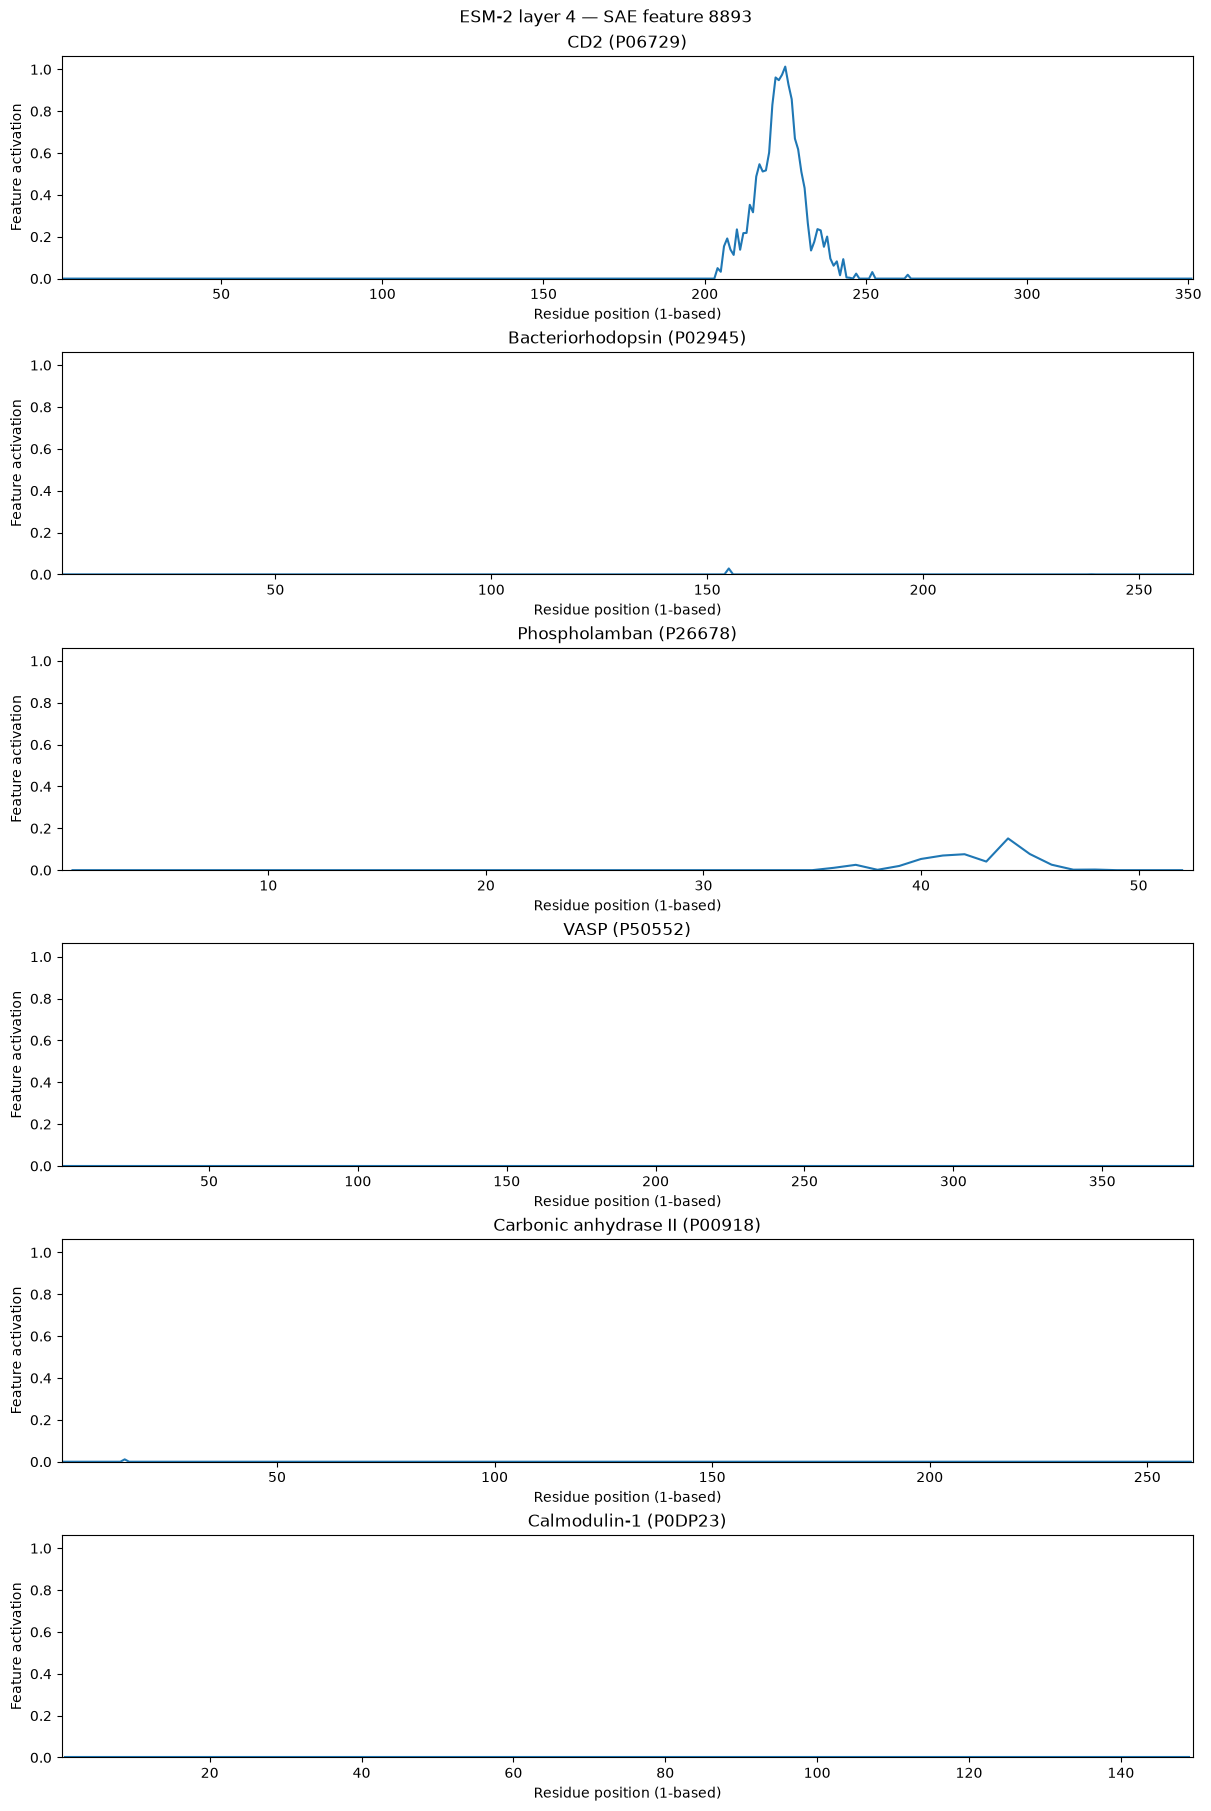

In [24]:
# Compare the same SAE feature across all six development proteins.
feature_id = 8893
protein_names = {
    'P06729': 'CD2',
    'P02945': 'Bacteriorhodopsin',
    'P26678': 'Phospholamban',
    'P50552': 'VASP',
    'P00918': 'Carbonic anhydrase II',
    'P0DP23': 'Calmodulin-1',
}

fig, axes = plt.subplots(
    nrows=6, ncols=1, figsize=(12, 18),
    sharey=True, constrained_layout=True,
)
fig.suptitle(f"ESM-2 layer {layer} — SAE feature {feature_id}")

for ax, (accession, protein_name) in zip(axes, protein_names.items()):
    sequence = amino_acid_dict[accession]
    protein_activations = activations_by_protein[accession]
    positions = np.arange(1, len(sequence) + 1)

    ax.plot(positions, protein_activations[:, feature_id])
    ax.set(
        xlabel="Residue position (1-based)",
        ylabel="Feature activation",
        title=f"{protein_name} ({accession})",
        xlim=(0.5, len(sequence) + 0.5),
    )

# Use a common y-axis scale to compare activation strengths.
axes[0].set_ylim(bottom=0)
plt.show();

In [25]:
from functools import partial
from helper import summarise_activations

# Bind the data once so calls still need only the accession and feature ID.
summarise_activations = partial(
    summarise_activations,
    amino_acid_dict=amino_acid_dict,
    activations_by_protein=activations_by_protein,
)

In [26]:
# Print one feature-5712 summary table for each of the six proteins.
for accession in amino_acid_dict:
    summarise_activations(accession, feature_id=feature_id)
    print()  # Separate the tables with a blank line.

P06729 — feature 8893; activation statistics ×100 (not percentages)
            Count    Mean     Q1  Median      Q3
Amino acid                                      
A              16  4.1816 0.0000  0.0000  0.0000
C               6  9.1104 0.0000  0.0000  0.0000
D              17  0.6664 0.0000  0.0000  0.0000
E              19  0.3000 0.0000  0.0000  0.0000
F              12  9.9355 0.0000  0.0000  0.0000
G              19 11.2654 0.0000  0.0000  9.5931
H              12  0.0000 0.0000  0.0000  0.0000
I              21  7.0003 0.0000  0.0000  0.0000
K              39  1.7472 0.0000  0.0000  0.0000
L              25 13.5760 0.0000  0.0000  0.0000
M               4 24.3512 0.0000  0.0000 24.3512
N              13  0.0317 0.0000  0.0000  0.0000
P              32  0.1563 0.0000  0.0000  0.0000
Q              19  0.3250 0.0000  0.0000  0.0000
R              17  2.2511 0.0000  0.0000  1.8415
S              29  2.9173 0.0000  0.0000  0.0000
T              23  1.0286 0.0000  0.0000  0.0000
V

In [34]:
# GPT 6.1 Sol High Effort helped with the code implementation for comparison with UniProt annotations for Feature 8893

### Feature 8893: comparison with UniProt membrane annotations

The cells below recreate the six-protein plot with **UniProt-annotated transmembrane segments shaded in gold**, then explain the evidence for a provisional membrane-related interpretation. They always investigate **feature 8893**, independently of the exploratory `feature_id` selected above.

The annotation snapshot in `data/reference/feature_8893_uniprot_evidence.json` contains the exact transmembrane feature objects, sequences and entry versions from the three UniProt records used for the original plot, retrieved **17 November 2026**. The cells use that snapshot without new downloads or model inference. Links below open the live records, whose annotations may change; the saved snapshot fixes the evidence used here. Sequences are checked against our saved analysis before using residue coordinates.

Only **CD2, phospholamban and bacteriorhodopsin** had their membrane annotations inspected for this comparison. The other three proteins remain in the plot as activation comparisons; an unshaded panel does not establish that UniProt has no membrane annotations for that protein.

In [27]:
import json
from html import escape
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.patches import Patch

membrane_feature_id = 8893
membrane_protein_names = {
    'P06729': 'CD2',
    'P02945': 'Bacteriorhodopsin',
    'P26678': 'Phospholamban',
    'P50552': 'VASP',
    'P00918': 'Carbonic anhydrase II',
    'P0DP23': 'Calmodulin-1',
}

evidence_path = Path('data/reference/feature_8893_uniprot_evidence.json')
uniprot_snapshot = json.loads(evidence_path.read_text())
if uniprot_snapshot['format_version'] != 1:
    raise ValueError('Unsupported UniProt evidence snapshot format.')
uniprot_evidence = uniprot_snapshot['records']
transmembrane_regions = {}

for accession, record in uniprot_evidence.items():
    if record['sequence']['value'] != amino_acid_dict[accession]:
        raise ValueError(f'{accession}: UniProt and saved analysis sequences differ.')
    regions = []
    for feature in record['features']:
        start = feature['location']['start']
        end = feature['location']['end']
        if start['modifier'] != 'EXACT' or end['modifier'] != 'EXACT':
            raise ValueError(f'{accession}: uncertain region boundaries need review.')
        if not 1 <= start['value'] <= end['value'] <= len(amino_acid_dict[accession]):
            raise ValueError(f'{accession}: transmembrane region is outside the sequence.')
        regions.append((start['value'], end['value']))
    transmembrane_regions[accession] = regions

print(f"Loaded annotation snapshot from {uniprot_snapshot['retrieved_on']}.")
print('Sequence identity and 1-based inclusive region coordinates checked for all three records.')

Loaded annotation snapshot from 2026-11-17.
Sequence identity and 1-based inclusive region coordinates checked for all three records.


#### Exact UniProt annotations and their evidence

Each row below comes from one `features` object with `type: "Transmembrane"` in the saved UniProt response. Positions are **1-based and inclusive**. The evidence column preserves the code and source attached to that specific region.

- [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/): match to sequence model evidence used in manual assertion. This supports CD2's **210–235** annotation through sequence analysis.
- [ECO:0000305](https://evidenceontology.org/term/ECO%3A0000305/): curator inference used in manual assertion. This supports phospholamban's **32–52** annotation.
- [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/): experimental evidence used in manual assertion.
- [ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/): combinatorial computational and experimental evidence used in manual assertion. Bacteriorhodopsin's regions include this code with a PDB reference, alongside the experimental literature references.

**The CD2 and phospholamban transmembrane feature objects do not attach a PubMed or PDB reference to their evidence code.** We therefore retain their sequence-analysis/curator-inference status. For bacteriorhodopsin, each of the seven annotated helices has links to [PubMed 10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/), [PubMed 28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/) and [PDB 1C3W](https://www.rcsb.org/structure/1C3W). These are the references UniProt attaches to those boundaries; this notebook does not independently reassess the underlying experiments.

See also [UniProt's evidence documentation](https://www.uniprot.org/help/evidences).

In [28]:
def region_evidence_link(evidence):
    code = evidence['evidenceCode']
    code_link = f"[{code}](https://evidenceontology.org/term/{code.replace(':', '%3A')}/)"
    source, identifier = evidence.get('source'), evidence.get('id')
    if source == 'PubMed':
        return f'{code_link}; [PubMed:{identifier}](https://pubmed.ncbi.nlm.nih.gov/{identifier}/)'
    if source == 'PDB':
        return f'{code_link}; [PDB:{identifier}](https://www.rcsb.org/structure/{identifier})'
    if source or identifier:
        return f'{code_link}; {source}:{identifier}'
    return f'{code_link}; no source reference attached'

evidence_lines = [
    '| Protein | Residues | UniProt description | Evidence attached to this region | Record links |',
    '|---|---|---|---|---|',
]
version_lines = ['**Snapshot entry versions** (all three sequences match the activation archive):', '']

for accession, record in uniprot_evidence.items():
    for feature in record['features']:
        start = feature['location']['start']['value']
        end = feature['location']['end']['value']
        attached = '<br>'.join(region_evidence_link(e) for e in feature.get('evidences', []))
        description = feature.get('description', '').replace('|', '&#124;')
        evidence_lines.append(
            f"| {membrane_protein_names[accession]} ({accession}) | {start}–{end} | "
            f"{description} | {attached} | [Entry]({record['entry_url']}); "
            f"[JSON]({record['source_url']}) |"
        )
    audit = record['entryAudit']
    version_lines.append(
        f"- **{accession}**: entry version {audit['entryVersion']}; "
        f"sequence version {audit['sequenceVersion']}; "
        f"last annotation update {audit['lastAnnotationUpdateDate']}."
    )

display(Markdown('\n'.join(evidence_lines)))
display(Markdown('\n'.join(version_lines)))

| Protein | Residues | UniProt description | Evidence attached to this region | Record links |
|---|---|---|---|---|
| CD2 (P06729) | 210–235 | Helical | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); no source reference attached | [Entry](https://www.uniprot.org/uniprotkb/P06729/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P06729.json) |
| Phospholamban (P26678) | 32–52 | Helical | [ECO:0000305](https://evidenceontology.org/term/ECO%3A0000305/); no source reference attached | [Entry](https://www.uniprot.org/uniprotkb/P26678/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P26678.json) |
| Bacteriorhodopsin (P02945) | 23–42 | Helical; Name=Helix A | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |
| Bacteriorhodopsin (P02945) | 57–75 | Helical; Name=Helix B | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |
| Bacteriorhodopsin (P02945) | 93–109 | Helical; Name=Helix C | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |
| Bacteriorhodopsin (P02945) | 121–140 | Helical; Name=Helix D | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |
| Bacteriorhodopsin (P02945) | 148–167 | Helical; Name=Helix E | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |
| Bacteriorhodopsin (P02945) | 186–204 | Helical; Name=Helix F | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |
| Bacteriorhodopsin (P02945) | 217–236 | Helical; Name=Helix G | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:10452895](https://pubmed.ncbi.nlm.nih.gov/10452895/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed:28008064](https://pubmed.ncbi.nlm.nih.gov/28008064/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB:1C3W](https://www.rcsb.org/structure/1C3W) | [Entry](https://www.uniprot.org/uniprotkb/P02945/entry#subcellular_location); [JSON](https://rest.uniprot.org/uniprotkb/P02945.json) |

**Snapshot entry versions** (all three sequences match the activation archive):

- **P06729**: entry version 248; sequence version 2; last annotation update 2026-11-04.
- **P26678**: entry version 223; sequence version 1; last annotation update 2026-11-04.
- **P02945**: entry version 217; sequence version 2; last annotation update 2026-11-04.

In [29]:
# Expand a record to inspect its exact Transmembrane feature JSON.
# Only the relevant feature type was extracted; feature objects are unchanged.
for accession, record in uniprot_evidence.items():
    raw_feature_json = json.dumps(record['features'], indent=2)
    display(HTML(
        f'<details><summary>{accession}: exact UniProt Transmembrane feature JSON</summary>'
        f'<pre>{escape(raw_feature_json)}</pre></details>'
    ))

#### Measure the overlap before interpreting the feature

For each checked protein, **activation inside annotated membrane regions (%)** is:

`100 × sum(8893 activations inside those regions) / sum(8893 activations across the protein)`

This measures the share of activation magnitude in those regions. It is not a probability, a percentage of residues, or a validated classifier score. Nonzero-residue counts below use the exact condition `activation > 0`; small positive responses remain included. `Not checked` means no membrane-annotation record was inspected for that protein in this comparison.

In [30]:
overlap_rows = []
for accession, protein_name in membrane_protein_names.items():
    sequence = amino_acid_dict[accession]
    values = activations_by_protein[accession][:, membrane_feature_id].astype(np.float64)
    total = values.sum()
    row = {
        'Accession': accession,
        'Protein': protein_name,
        'Peak activation': values.max(),
        'Peak position': int(values.argmax() + 1) if total > 0 else None,
        'Nonzero residues': int(np.count_nonzero(values > 0)),
        'Annotated membrane regions': 'Not checked',
        'Activation inside membrane (%)': np.nan,
        'Active residues inside membrane': np.nan,
        'Active residues outside membrane': np.nan,
        'Distinct amino acids active inside membrane': np.nan,
    }
    if accession in transmembrane_regions:
        membrane_mask = np.zeros(len(sequence), dtype=bool)
        for start, end in transmembrane_regions[accession]:
            membrane_mask[start - 1:end] = True  # 1-based inclusive -> NumPy slice
        active_inside = membrane_mask & (values > 0)
        row.update({
            'Annotated membrane regions': ', '.join(
                f'{start}–{end}' for start, end in transmembrane_regions[accession]
            ),
            'Activation inside membrane (%)': 100 * values[membrane_mask].sum() / total if total > 0 else np.nan,
            'Active residues inside membrane': int(np.count_nonzero(active_inside)),
            'Active residues outside membrane': int(np.count_nonzero((~membrane_mask) & (values > 0))),
            'Distinct amino acids active inside membrane': len(set(np.array(list(sequence))[active_inside])),
        })
    overlap_rows.append(row)

feature_8893_overlap = pd.DataFrame(overlap_rows).set_index('Accession')
display(feature_8893_overlap.style.format({
    'Peak activation': '{:.6f}',
    'Peak position': '{:.0f}',
    'Activation inside membrane (%)': '{:.2f}',
    'Active residues inside membrane': '{:.0f}',
    'Active residues outside membrane': '{:.0f}',
    'Distinct amino acids active inside membrane': '{:.0f}',
}, na_rep='—'))

,Protein,Peak activation,Peak position,Nonzero residues,Annotated membrane regions,Activation inside membrane (%),Active residues inside membrane,Active residues outside membrane,Distinct amino acids active inside membrane
Accession,,,,,,,,,
P06729,CD2,1.013146,225,46,210–235,88.98,26,20,11
P02945,Bacteriorhodopsin,0.028227,155,2,"23–42, 57–75, 93–109, 121–140, 148–167, 186–204, 217–236",97.87,1,1,1
P26678,Phospholamban,0.151724,44,13,32–52,100.00,13,0,3
P50552,VASP,0.000000,—,0,Not checked,—,—,—,—
P00918,Carbonic anhydrase II,0.011241,15,1,Not checked,—,—,—,—
P0DP23,Calmodulin-1,0.000000,—,0,Not checked,—,—,—,—


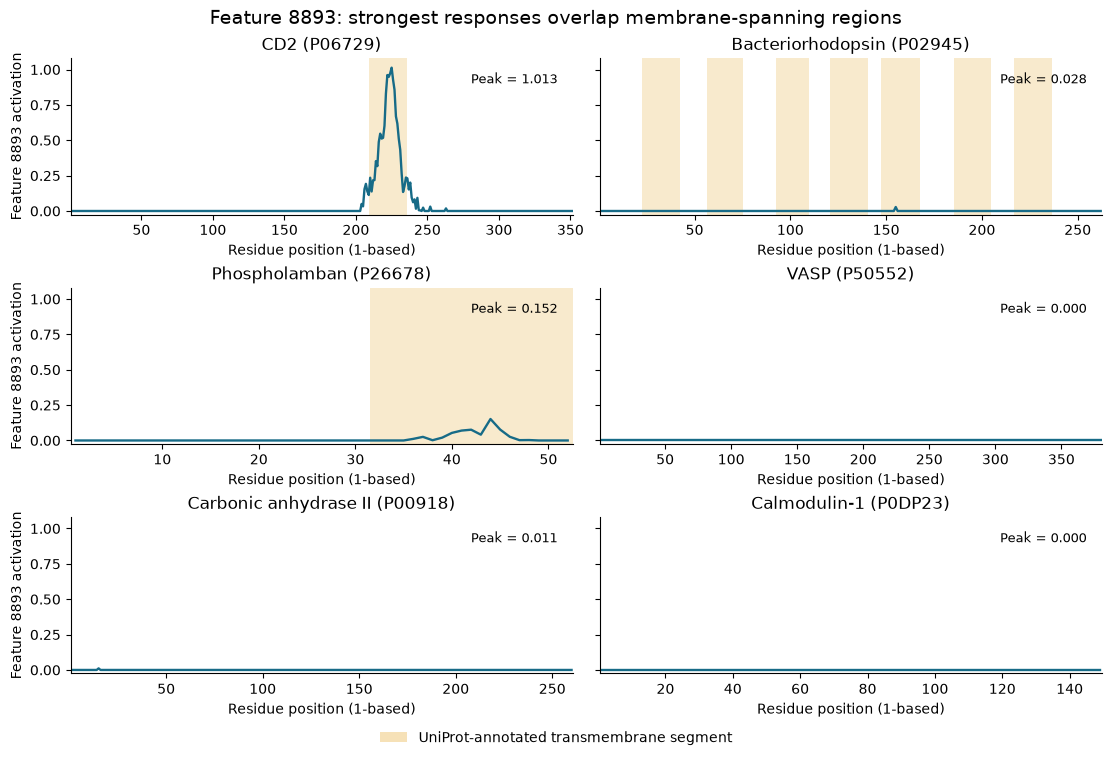

Saved outputs/feature_8893_membrane_overlap.png


In [31]:
# Recreate and save the annotated six-protein plot, using the snapshot boundaries.
fig, axes = plt.subplots(3, 2, figsize=(11, 7.5), sharey=True, layout='constrained')

for ax, (accession, protein_name) in zip(axes.flat, membrane_protein_names.items()):
    sequence = amino_acid_dict[accession]
    values = activations_by_protein[accession][:, membrane_feature_id]
    ax.plot(np.arange(1, len(sequence) + 1), values, color='#176b87', lw=1.7)
    for start, end in transmembrane_regions.get(accession, []):
        ax.axvspan(start - 0.5, end + 0.5, color='#e9b44c', alpha=0.28, lw=0)
    ax.set(
        title=f'{protein_name} ({accession})',
        xlim=(0.5, len(sequence) + 0.5),
        ylim=(-0.025, 1.08),
        xlabel='Residue position (1-based)',
    )
    ax.text(0.97, 0.91, f'Peak = {values.max():.3f}', ha='right', va='top', transform=ax.transAxes, fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel(f'Feature {membrane_feature_id} activation')

fig.suptitle('Feature 8893: strongest responses overlap membrane-spanning regions', fontsize=14)
fig.legend(
    handles=[Patch(facecolor='#e9b44c', alpha=0.4, label='UniProt-annotated transmembrane segment')],
    loc='outside lower center', frameon=False,
)

membrane_plot_path = Path('outputs/feature_8893_membrane_overlap.png')
membrane_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(membrane_plot_path, dpi=180)
plt.show()
print(f'Saved {membrane_plot_path}')

In [35]:
cd2_result = feature_8893_overlap.loc['P06729']
pln_result = feature_8893_overlap.loc['P26678']
br_result = feature_8893_overlap.loc['P02945']
cd2_regions = cd2_result['Annotated membrane regions']
pln_regions = pln_result['Annotated membrane regions']

display(Markdown(f"""
**What the evidence supports:** CD2 has {cd2_result['Activation inside membrane (%)']:.2f}% of its
total feature-8893 activation inside its UniProt-annotated transmembrane segment ({cd2_regions}),
with responses across {cd2_result['Distinct amino acids active inside membrane']:.0f} amino-acid types
there. Phospholamban has {pln_result['Activation inside membrane (%)']:.2f}% inside its annotated
segment ({pln_regions}). Bacteriorhodopsin has seven annotated membrane-spanning helices but
a much weaker peak ({br_result['Peak activation']:.3f}, compared with
{cd2_result['Peak activation']:.3f} for CD2).

**Provisional hypothesis:** feature 8893 preferentially responds to a subset of (potentially) hydrophobic,
membrane-spanning sequence contexts. The overlap gives a biological interpretation to test;
it does not establish a universal membrane detector or isolate what sequence property drives it.
The UniProt annotations describe membrane regions; the proposed meaning of feature ID 8893 is
our own inference from their overlap with the model's activations. (this has ended up being the thing we explore more!)
"""))


**What the evidence supports:** CD2 has 88.98% of its
total feature-8893 activation inside its UniProt-annotated transmembrane segment (210–235),
with responses across 11 amino-acid types
there. Phospholamban has 100.00% inside its annotated
segment (32–52). Bacteriorhodopsin has seven annotated membrane-spanning helices but
a much weaker peak (0.028, compared with
1.013 for CD2).

**Provisional hypothesis:** feature 8893 preferentially responds to a subset of (potentially) hydrophobic,
membrane-spanning sequence contexts. The overlap gives a biological interpretation to test;
it does not establish a universal membrane detector or isolate what sequence property drives it.
The UniProt annotations describe membrane regions; the proposed meaning of feature ID 8893 is
our own inference from their overlap with the model's activations. (this has ended up being the thing we explore more!)


VASP, Carbonic anhydrase II, and Calmodulin-1 don't have a membrane spanning segment for us to to test the hypothesis that layer 4 feature 8893 identifies a transmembrane region. But it looks promising so far from the ones that do.

According to UniProt, P02945 makes 7 passes through the cell membrane, and those residue sections show high feature high activations - so promising so far.

In [33]:
# add hydrophobic regions outside membranes, and compare the same amino-acid types inside and outside the annotated regions
# these controls would help distinguish amino-acid composition from broader sequence context